#                                    Airfoil Self-Noise Veri Seti Üzerinde Regresyon Modelleri


**Veri Seti:** NASA Airfoil Self-Noise Dataset   

---

## 1. Veri Seti Tanıtımı

Bu veri seti NASA tarafından düşük hızlı rüzgar tünelinde gerçekleştirilen aerodinamik ve akustik testlerden elde edilmiştir.  
Toplam **1503 gözlem** ve **6 değişken** içermektedir.

### Değişkenler:
| Değişken | Açıklama | Birim |
|----------|----------|-------|
| `f` | Ses frekansı | Hz |
| `alpha` | Saldırı açısı (angle of attack) | derece |
| `c` | Kanat uzunluğu (chord length) | metre |
| `U_infinity` | Akış hızı | m/s |
| `delta` | Emme tarafı yer sınırı tabakası kalınlığı | metre |
| `SSPL` | **Hedef değişken** — Ölçeklendirilmiş ses basıncı seviyesi | dB |

**Amaç:** `SSPL` (ses basıncı) değerini diğer 5 bağımsız değişken kullanarak tahmin etmektir.

---
Bu çalışmada kullanılan "Airfoil Self-Noise" veri seti,NASA tarafından Langley Araştırma Merkezi'nde yapılan rüzgar tüneli testlerinden 
elde edilmiştir.Havacılık endüstrisinde uçak kanatlarının (airfoil) havayı yararken çıkardığı ses hem çevresel gürültü kirliliği hem de uçağın aerodinamik verimliliği açısından kritik bir problemdir. Bir kanat profili ne kadar çok "kendi kendine gürültü"
(self-noise) üretiyorsa bu genellikle hava akışının o kadar düzensiz (türbülanslı) olduğunu gösterir.
Bu projede amacımız; fiziksel bir rüzgar tüneli deneyine gerek kalmadan kanadın teknik özelliklerini (frekans, hız, açı vb.) kullanarak üreteceği Ses Basınç Seviyesini (desibel) tahmin edebilecek en iyi makine öğrenmesi modelini bulmaktır.

***Değişkenlerimizin Anlamı:***

**Frekans (Hz):** Sesin perdesi. (Düşük mü gürültülü mü?)

**Hücum Açısı (°):** Kanadın rüzgara karşı duruş açısı. (Açı arttıkça türbülans artar mı?)

**Kanat Uzunluğu (m):** Kanadın fiziksel boyutu.

**Akış Hızı (m/s):** Uçağın veya rüzgarın hızı.

**Emme Tarafı Kalınlığı (m):** Kanat üzerindeki hava tabakasının kalınlığı

**Ses Seviyesi (dB) [Hedef]:** Tahmin etmeye çalıştığımız gürültü miktarı.

## 2. Kütüphanelerin ve Verinin Yüklenmesi 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sbn
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler, scale
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.cross_decomposition import PLSRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor, GradientBoostingRegressor

import statsmodels.api as sm
import statsmodels.formula.api as smf

plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

In [2]:
dat = pd.read_csv("C:/Users/huawei 1/OneDrive/Desktop/AirfoilSelfNoise.csv")
dt = dat.copy()
print(f'Satır sayısı: {dt.shape[0]}, Sütun sayısı: {dt.shape[1]}')
dt.head(10)

Satır sayısı: 1503, Sütun sayısı: 6


,f,alpha,c,U_infinity,delta,SSPL
0,800,0.0,0.3048,71.3,0.002663,126.201
1,1000,0.0,0.3048,71.3,0.002663,125.201
2,1250,0.0,0.3048,71.3,0.002663,125.951
3,1600,0.0,0.3048,71.3,0.002663,127.591
4,2000,0.0,0.3048,71.3,0.002663,127.461
5,2500,0.0,0.3048,71.3,0.002663,125.571
6,3150,0.0,0.3048,71.3,0.002663,125.201
7,4000,0.0,0.3048,71.3,0.002663,123.061
8,5000,0.0,0.3048,71.3,0.002663,121.301
9,6300,0.0,0.3048,71.3,0.002663,119.541


## 3.  Veri Analizi 

In [3]:
# Değişken tipleri ve eksik gözlem kontrolü
print('=== Değişken Bilgileri ===')
dt.info()

=== Değişken Bilgileri ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1503 entries, 0 to 1502
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   f           1503 non-null   int64  
 1   alpha       1503 non-null   float64
 2   c           1503 non-null   float64
 3   U_infinity  1503 non-null   float64
 4   delta       1503 non-null   float64
 5   SSPL        1503 non-null   float64
dtypes: float64(5), int64(1)
memory usage: 70.6 KB


Yapılan ön incelemede
Airfoil Self-Noise veri setinin 1503 gözlemden oluştuğu ve hiçbir değişkenin eksik gözlem (null) içermediği saptanmıştır. 
Tüm bağımsız değişkenler ve 'Ses Seviyesi' bağımlı değişkeni sayısal (nümerik) tiptedir.
Bu durum verinin herhangi bir kategorik dönüşüme ihtiyacı olmadığını gösterir.
"

In [4]:
print('=== Betimsel İstatistikler ===')
dt.describe().T

=== Betimsel İstatistikler ===


,count,mean,std,min,25%,50%,75%,max
f,1503.0,2886.380572,3152.573137,200.000000,800.000000,1600.000000,4000.000000,20000.000000
alpha,1503.0,6.782302,5.918128,0.000000,2.000000,5.400000,9.900000,22.200000
c,1503.0,0.136548,0.093541,0.025400,0.050800,0.101600,0.228600,0.304800
U_infinity,1503.0,50.860745,15.572784,31.700000,39.600000,39.600000,71.300000,71.300000
delta,1503.0,0.011140,0.013150,0.000401,0.002535,0.004957,0.015576,0.058411
SSPL,1503.0,124.835943,6.898657,103.380000,120.191000,125.721000,129.995500,140.987000


In [5]:
print('=== Eksik Gözlem Kontrolü ===')
print(dt.isnull().sum())
print(f'\nHerhangi bir eksik gözlem var mı? {dt.isnull().values.any()}')

=== Eksik Gözlem Kontrolü ===
f             0
alpha         0
c             0
U_infinity    0
delta         0
SSPL          0
dtype: int64

Herhangi bir eksik gözlem var mı? False


Eksik gözlemimiz yoktur.

=== Korelasyon Matrisi ===


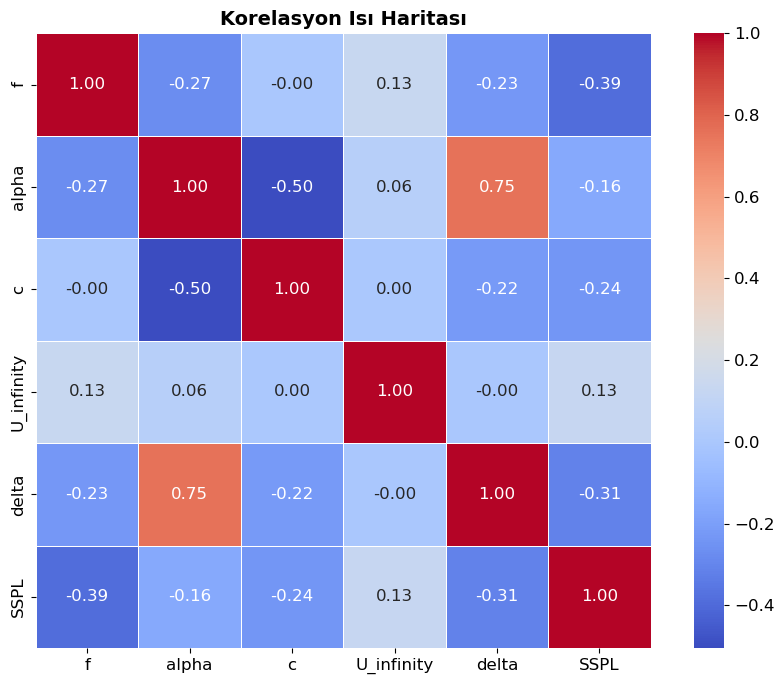


SSPL ile diğer değişkenler arasındaki korelasyon:
SSPL          1.000000
U_infinity    0.125103
alpha        -0.156108
c            -0.236162
delta        -0.312670
f            -0.390711
Name: SSPL, dtype: float64


In [6]:
print('=== Korelasyon Matrisi ===')
corr_matrix = dt.corr()

plt.figure(figsize=(9, 7))
sbn.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm',
            square=True, linewidths=0.5)
plt.title('Korelasyon Isı Haritası', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('\nSSPL ile diğer değişkenler arasındaki korelasyon:')
print(corr_matrix['SSPL'].sort_values(ascending=False))

**Yorum:** Korelasyon matrisine göre delta (yer sınırı tabakası kalınlığı) ile SSPL arasında negatif yönlü korelasyon gözlemlenmektedir. f (frekans) değişkeni de hedef değişken ile anlamlı bir ilişki içindedir. Değişkenler arası güçlü korelasyonlar çoklu doğrusal bağlantı (multicollinearity) sorununa yol açabileceğinden PCR ve PLS gibi boyut indirgeme yöntemleri bu veri seti için uygun olabilir.

****Korelasyon Analizi Özeti****

Veri setindeki değişkenlerin birbirleriyle olan ilişkilerini incelemek amacıyla oluşturulan korelasyon ısı haritasında öne çıkan bulgular şunlardır:
*En Güçlü Pozitif İlişki:* alpha ve delta değişkenleri arasında 0.75 değerinde yüksek pozitif bir korelasyon tespit edilmiştir. Bu durum bir değişkenin artışının diğeriyle güçlü bir şekilde doğru orantılı olduğunu gösterir.

*Negatif İlişkiler:* alpha ile c değişkenleri arasında orta düzeyde (-0.50) negatif bir ilişki bulunmaktadır. Benzer şekilde hedef değişken olan SSPL ile frekans (f) arasında -0.39 değerinde ters yönlü bir etkileşim gözlemlenmiştir.

*Hedef Değişken (SSPL) Analizi:* SSPL değeri üzerinde en belirgin negatif etkiye f (-0.39) ve delta (-0.31) değişkenleri sahipken; U_infinity (0.13) değişkeninin etkisi oldukça sınırlı kalmıştır.

*Bağımsız Değişkenler:* U_infinity değişkeninin c ve delta ile olan korelasyonunun 0.00 olması, bu değişkenlerin birbirinden tamamen bağımsız hareket ettiğini kanıtlamaktadır.

*Sonuç:* Model kurulumunda alpha ve delta arasındaki yüksek korelasyon, çoklu doğrusallık (multicollinearity) açısından dikkate alınmalıdır.

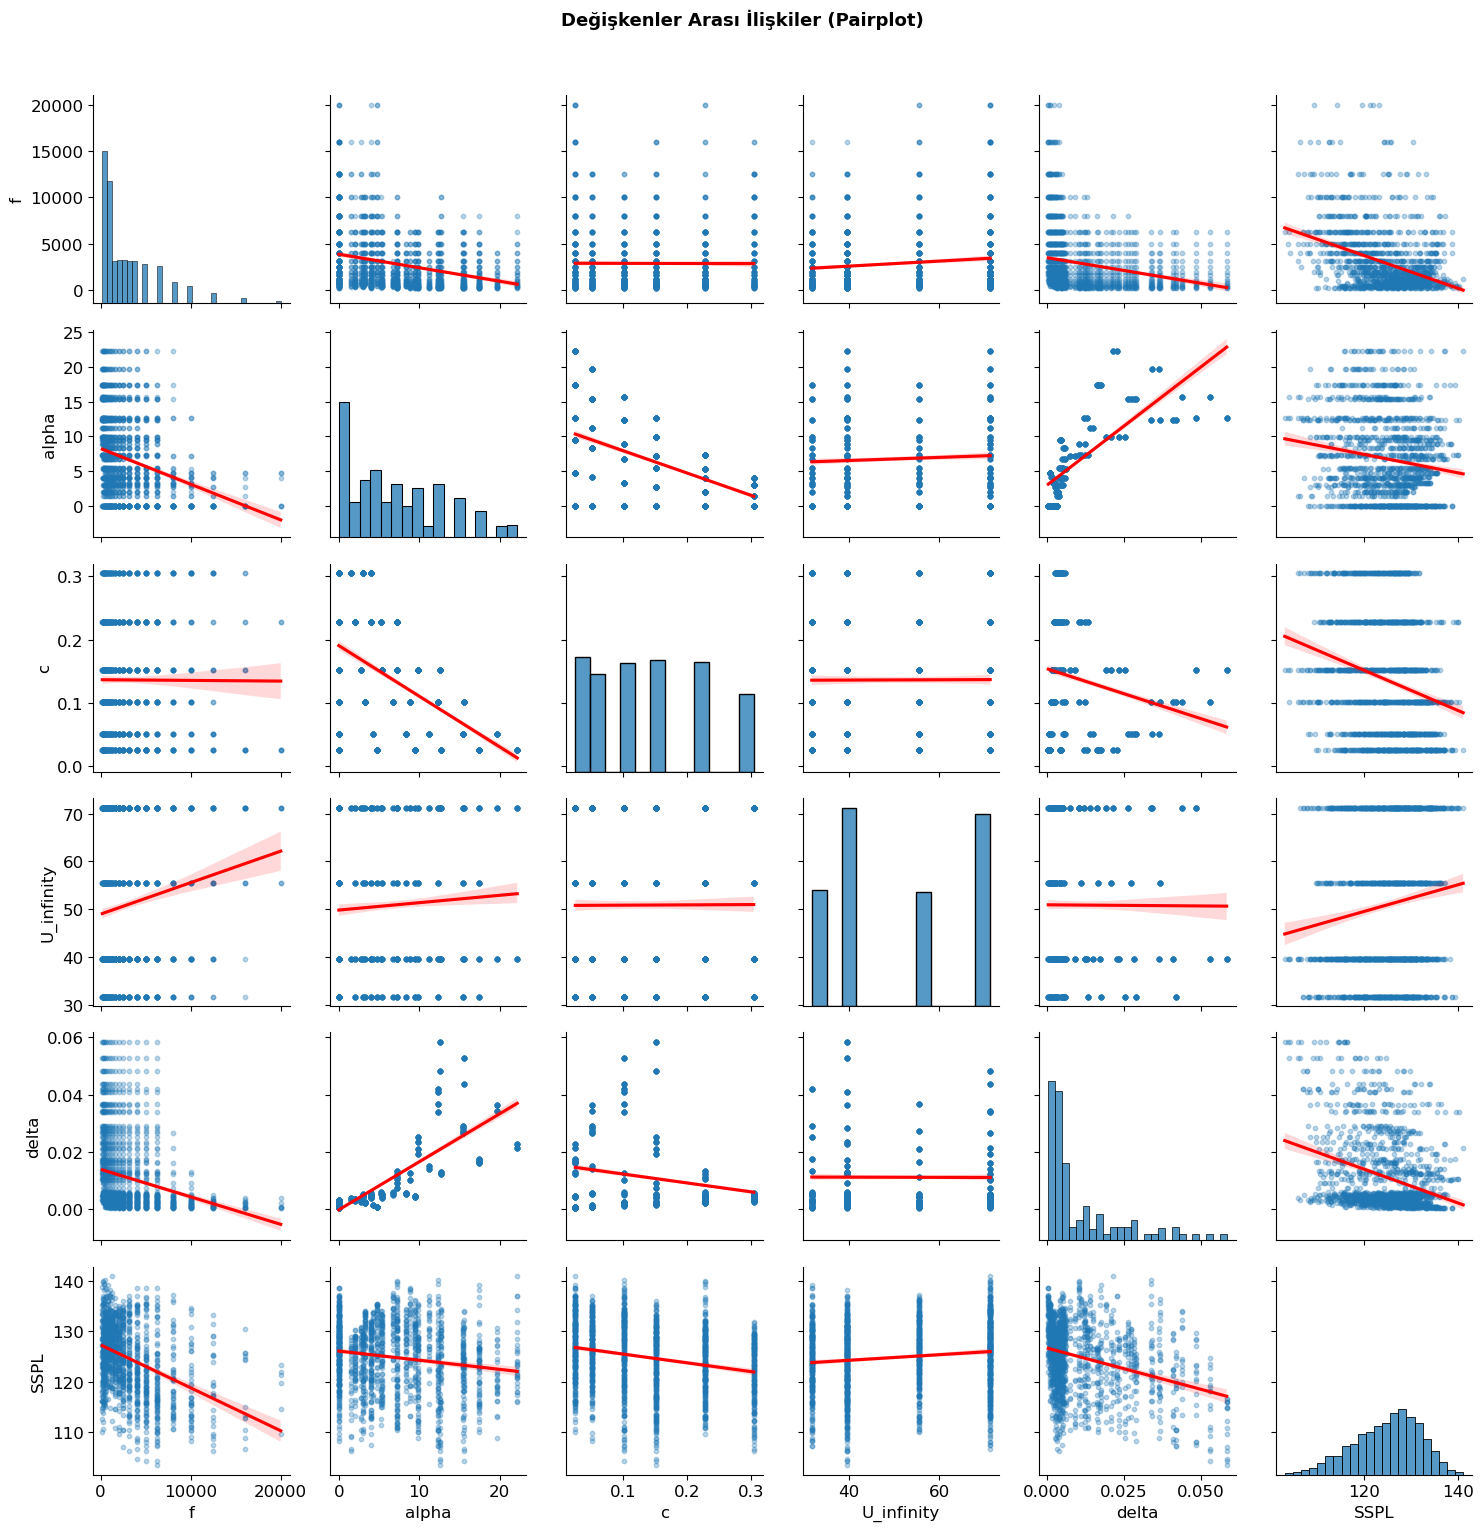

In [7]:
# Pairplot — değişkenler arası ilişki görselleştirmesi
sbn.pairplot(dt, kind='reg', plot_kws={'line_kws': {'color': 'red'}, 'scatter_kws': {'alpha': 0.3, 's': 10}})
plt.suptitle('Değişkenler Arası İlişkiler (Pairplot)', y=1.02, fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

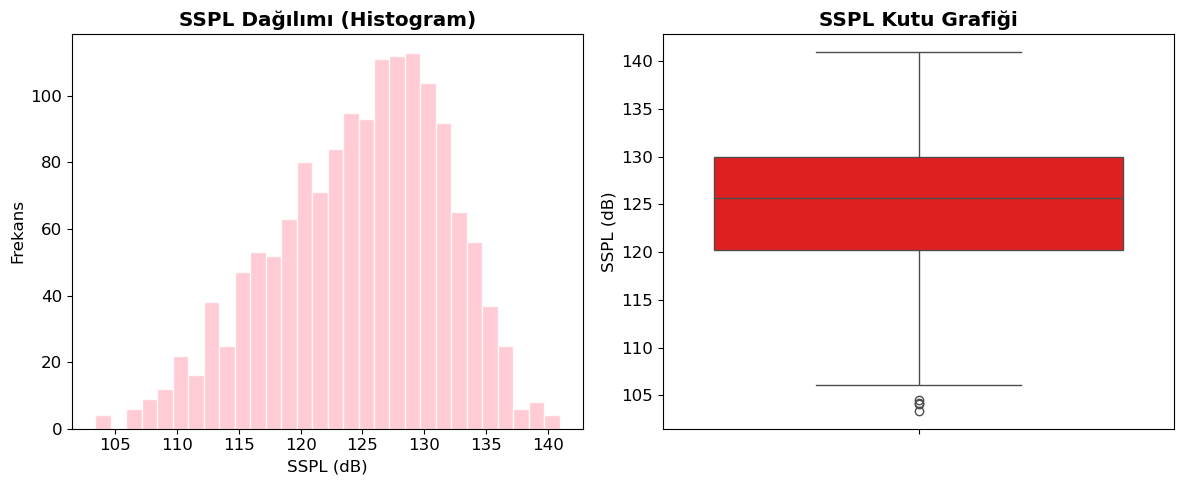

SSPL Ortalama: 124.836 dB
SSPL Std. Sapma: 6.899 dB
SSPL Min: 103.380 dB  |  Max: 140.987 dB


In [8]:
# Hedef değişkenin dağılımı
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].hist(dt['SSPL'], bins=30, color='pink', edgecolor='white', alpha=0.8)
axes[0].set_title('SSPL Dağılımı (Histogram)', fontweight='bold')
axes[0].set_xlabel('SSPL (dB)')
axes[0].set_ylabel('Frekans')

sbn.boxplot(y=dt['SSPL'], ax=axes[1], color='red')
axes[1].set_title('SSPL Kutu Grafiği', fontweight='bold')
axes[1].set_ylabel('SSPL (dB)')

plt.tight_layout()
plt.show()

print(f'SSPL Ortalama: {dt["SSPL"].mean():.3f} dB')
print(f'SSPL Std. Sapma: {dt["SSPL"].std():.3f} dB')
print(f'SSPL Min: {dt["SSPL"].min():.3f} dB  |  Max: {dt["SSPL"].max():.3f} dB')

**SSPL (Ses Basınç Seviyesi) Dağılım Analizi**

Hedef değişken olan SSPL verilerinin dağılımı incelendiğinde, verilerin 103.38 dB ile 140.98 dB aralığında yayılım gösterdiği ve 124.836 dB ortalama değerinde yoğunlaştığı görülmektedir. Histogram grafiği, verinin genel olarak normal dağılıma yakın bir eğilim sergilediğini ve örneklemin büyük çoğunluğunun 120-135 dB bandında kümelendiğini ortaya koymaktadır. Kutu grafiği  analizi ise medyan değerinin merkezi bir konumda olduğunu ve veri setinde istatistiksel süreci bozmayacak düzeyde çok az sayıda alt uç aykırı değer bulunduğunu doğrulamaktadır. Sonuç olarak SSPL değişkeninin dengeli dağılımı ve %70 eğitim - %30 test oranıyla yapılan veri ayrımı geliştirilecek tahminleme modelleri için güvenilir ve genellenebilir bir temel oluşturmaktadır.

## 4. Eğitim / Test Ayrımı

Tüm modellerde aynı eğitim/test bölünmesi kullanılarak modeller adil biçimde karşılaştırılacaktır. Veri seti %70 eğitim, %30 test olarak bölünmüştür.

In [9]:
X = dt.drop('SSPL', axis=1)
y = dt['SSPL']

x_egitim, x_test, y_egitim, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42)

# Sonuçları karşılaştırmak için sözlük
sonuclar = {}

---
## 5.Çoklu Doğrusal Regresyon

Çoklu doğrusal regresyon modeli, SSPL'nin tüm bağımsız değişkenlerle doğrusal ilişkisini modellemektedir.  


In [10]:
# statsmodels ile detaylı model özeti
lin_mod = smf.ols('SSPL ~ f + alpha + c + U_infinity + delta', data=dt)
mod_ols = lin_mod.fit()
print(mod_ols.summary())

                            OLS Regression Results                            
Dep. Variable:                   SSPL   R-squared:                       0.516
Model:                            OLS   Adj. R-squared:                  0.514
Method:                 Least Squares   F-statistic:                     318.8
Date:                Mon, 11 May 2026   Prob (F-statistic):          1.15e-232
Time:                        22:35:38   Log-Likelihood:                -4490.1
No. Observations:                1503   AIC:                             8992.
Df Residuals:                    1497   BIC:                             9024.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    132.8338      0.545    243.866      0.0

Gerçekleştirilen OLS regresyon analizi sonuçlarına göre, modelin bağımlı değişkeni olan SSPL üzerindeki açıklayıcılık oranı (R-squared) %51.6 olarak tespit edilmiştir.

In [11]:
# sklearn ile eğitim/test performansı
lin_model = LinearRegression()
lin_model.fit(x_egitim, y_egitim)

# Katsayılar
katsayilar = pd.DataFrame({'Değişken': X.columns, 'Katsayı': lin_model.coef_})
print(f'Sabit (Intercept): {lin_model.intercept_:.4f}')
print(katsayilar.to_string(index=False))

# Performans
preds_lin = lin_model.predict(x_test)
rmse_lin = np.sqrt(mean_squared_error(y_test, preds_lin))
r2_lin = r2_score(y_test, preds_lin)

print(f'\n--- Test Seti Performansı ---')
print(f'RMSE : {rmse_lin:.4f}')
print(f'R²   : {r2_lin:.4f}')

sonuclar['Doğrusal Regresyon'] = {'RMSE': rmse_lin, 'R2': r2_lin}

Sabit (Intercept): 132.4778
  Değişken     Katsayı
         f   -0.001273
     alpha   -0.365258
         c  -34.616963
U_infinity    0.099991
     delta -157.201730

--- Test Seti Performansı ---
RMSE : 4.8670
R²   : 0.4983


## Doğrusal Regresyon Sonuçları

### Model Katsayılarının İncelenmesi

Modelin oluşturduğu denklemde sabit değer **(Intercept) 132.4778** olarak belirlenmiştir.
Bağımsız değişkenlerin gürültü (SSPL) üzerindeki etkileri aşağıdaki tabloda özetlenmiştir:

| Değişken | Katsayı | Yön | Yorum |
|----------|---------|-----|-------|
| Sabit (Intercept) | 132.4778 | — | Tüm değişkenler sıfırken beklenen SSPL |
| U_infinity (Hız) | +0.0999 |  Pozitif | Hız arttıkça gürültü artar |
| c (Kanat Boyu) | −34.6169 |  Negatif | Güçlü azaltıcı etki |
| delta (Sınır Tabakası) | −157.2017 | Negatif | Modeldeki en baskın negatif etken |
| alpha (Hücum Açısı) | −0.3653 |  Negatif | Her 1° artış ≈ 0.36 dB düşüş |
| f (Frekans) | −0.0012 |  Negatif | Negatif ancak birim bazlı etkisi çok küçük |

---

### Performans Değerlendirmesi

| Metrik | Değer | Yorum |
|--------|-------|-------|
| **R² (Belirlilik Katsayısı)** | **0.4983** | Varyansın ~%50'si açıklanmaktadır |
| **RMSE (Kök Ortalama Kare Hata)** | **4.8670 dB** | Ortalama tahmin hatası |

**R²:** Model, gürültü seviyesindeki değişimlerin yaklaşık **%50'sini** açıklayabilmektedir.
Temel eğilimler yakalanmış olmakla birlikte verideki varyansın yarısı henüz açıklanamamaktadır.

**RMSE:** Tahminler gerçek değerlerden ortalama **4.87 dB** sapma göstermektedir.
SSPL değerlerinin 103–140 dB aralığında olduğu düşünüldüğünde bu hata payı doğrusal
bir model için makul, ancak geliştirilmeye açıktır.

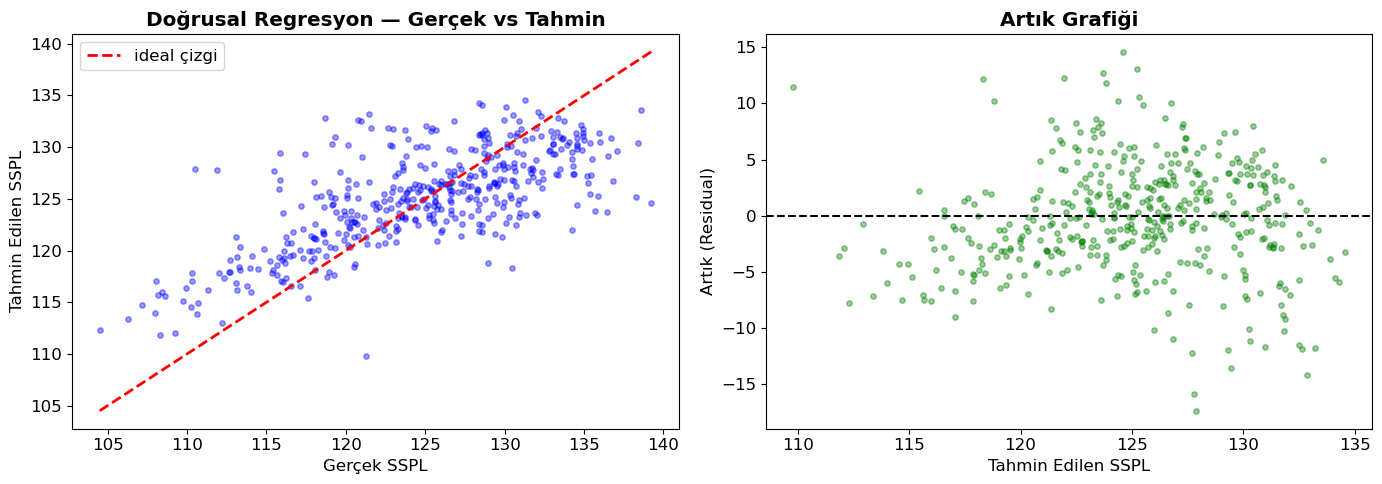

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gerçek vs Tahmin
axes[0].scatter(y_test, preds_lin, alpha=0.4, color='blue', s=15)
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label='ideal çizgi')
axes[0].set_xlabel('Gerçek SSPL')
axes[0].set_ylabel('Tahmin Edilen SSPL')
axes[0].set_title('Doğrusal Regresyon — Gerçek vs Tahmin', fontweight='bold')
axes[0].legend()

# Artıklar
artiklar = y_test - preds_lin
axes[1].scatter(preds_lin, artiklar, alpha=0.4, color='green', s=15)
axes[1].axhline(0, color='black', lw=1.5, linestyle='--')
axes[1].set_xlabel('Tahmin Edilen SSPL')
axes[1].set_ylabel('Artık (Residual)')
axes[1].set_title('Artık Grafiği', fontweight='bold')

plt.tight_layout()
plt.show()


**Yorum:** Doğrusal regresyon modeli istatistiksel açıdan anlamlı sonuçlar üretmektedir (p < 0.05). Ancak artık grafiğinde sistematik bir örüntü gözlemlenmesi, doğrusal olmayan ilişkilerin varlığına işaret etmektedir. 
Bu durum, doğrusal olmayan modellerin daha iyi performans gösterebileceğini düşündürmektedir.

## 6. Temel Bileşenler Regresyonu (PCR)

Değişkenler arasında yüksek korelasyon varsa çoklu doğrusal bağlantı sorunu ortaya çıkar. PCR, PCA ile bağımsız bileşenler türeterek bu sorunu giderir. Değişkenlerin **standartlaştırma** zorunludur.

In [13]:
cv_kfold = KFold(n_splits=5, shuffle=True, random_state=42)
pca = PCA()
x_egitim_pca = pca.fit_transform(scale(x_egitim))

# Açıklanan varyans oranları
aciklanan_varyans = np.cumsum(pca.explained_variance_ratio_)
print('Kümülatif Açıklanan Varyans Oranları:')
for i, v in enumerate(aciklanan_varyans, 1):
    print(f'  {i} bileşen: %{v*100:.2f}')

# Her bileşen sayısı için MSE hesapla (Cross-Validation)
mse_pcr = []
regr_pcr = LinearRegression()
for i in np.arange(1, x_egitim_pca.shape[1] + 1):
    score = -1 * cross_val_score(
        regr_pcr, x_egitim_pca[:, :i], y_egitim,
        cv=cv_kfold, scoring='neg_mean_squared_error'
    ).mean()
    mse_pcr.append(score)

optimum_n = np.argmin(mse_pcr) + 1
print(f'\nOptimum bileşen sayısı: {optimum_n}  (MSE: {mse_pcr[optimum_n-1]:.4f})')

Kümülatif Açıklanan Varyans Oranları:
  1 bileşen: %42.38
  2 bileşen: %64.59
  3 bileşen: %83.09
  4 bileşen: %96.57
  5 bileşen: %100.00

Optimum bileşen sayısı: 5  (MSE: 22.9475)


## PCR (Principal Component Regression) Sonuçları

### Varyans Analizi: Veri Ne Kadar Temsil Ediliyor?

PCA işlemi, elindeki 5 farklı değişkeni (f, alpha, c, U_infinity, delta) yeni "bileşenlere" dönüştürdü.

- **İlk 3 bileşen:** Verideki bilginin **%83.09'unu** taşıyor. Genellikle veri setlerinde ilk birkaç bileşen bilginin büyük kısmını özetler.
- **4 bileşen:** Bilginin **%96.57'sini** kapsıyor. Bu, aslında 5 değişken yerine 4 değişkenle bile veriyi neredeyse tam kapasiteyle temsil edebileceğin anlamına gelir.
- **5 bileşen:** Beklendiği üzere verinin **%100'ünü** açıklıyor (çünkü zaten toplamda 5 değişken var).

---

### Optimum Bileşen Sayısı ve Model Kararı

Modelin en düşük hatayı (MSE) hangi noktada verdiğini bulmak için yapılan Cross-Validation (Çapraz Doğrulama) sonucuna göre optimum bileşen sayısı **5** olarak belirlenmiştir.

Bu sonuç kritik bir anlama gelir: **Model, boyut indirgemesi yapmayı reddediyor.**

- Eğer optimum sayı **2 veya 3** çıksaydı → *"Verideki bazı değişkenler gereksiz, onları atarsak model daha sağlıklı çalışır"* diyebilirdik.
- Ancak optimum sayının **5** çıkması, veri setindeki her bir değişkenin gürültü tahmininde **vazgeçilmez** bir bilgi sunduğunu gösterir.
- Boyutu küçültmek, modelin performansını (tahmin gücünü) **düşürmektedir**.

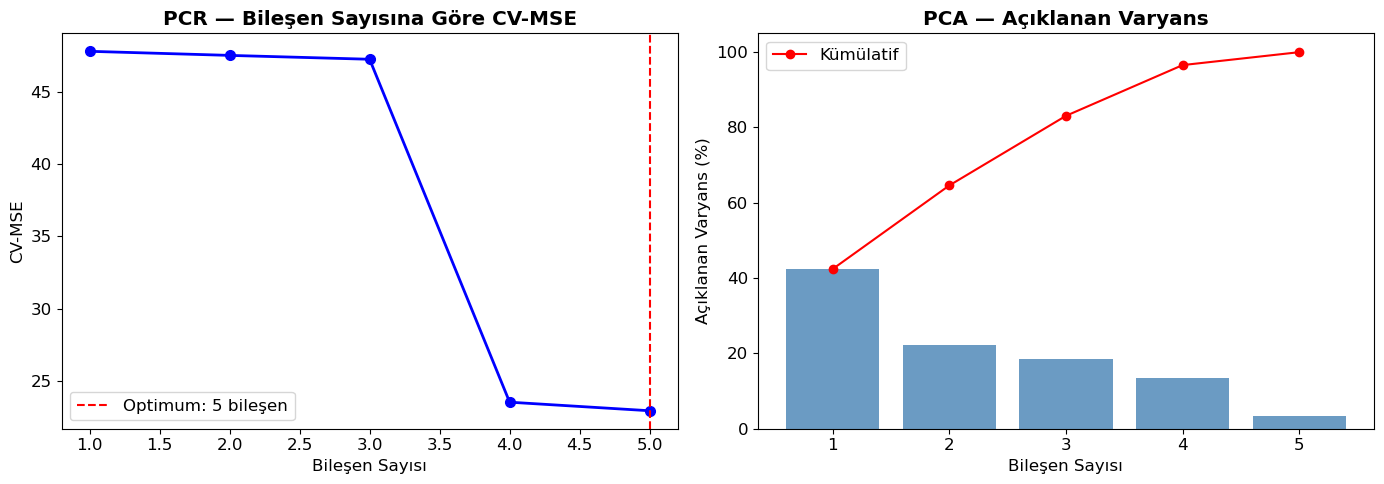

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, len(mse_pcr)+1), mse_pcr, 'bo-', lw=2, markersize=7)
axes[0].axvline(optimum_n, color='red', linestyle='--', label=f'Optimum: {optimum_n} bileşen')
axes[0].set_xlabel('Bileşen Sayısı')
axes[0].set_ylabel('CV-MSE')
axes[0].set_title('PCR — Bileşen Sayısına Göre CV-MSE', fontweight='bold')
axes[0].legend()

axes[1].bar(range(1, len(aciklanan_varyans)+1), pca.explained_variance_ratio_*100, color='steelblue', alpha=0.8)
axes[1].plot(range(1, len(aciklanan_varyans)+1), aciklanan_varyans*100, 'r-o', label='Kümülatif')
axes[1].set_xlabel('Bileşen Sayısı')
axes[1].set_ylabel('Açıklanan Varyans (%)')
axes[1].set_title('PCA — Açıklanan Varyans', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

## 4. Model Analizi: PCR ve PCA Bileşen Optimizasyonu

### 4.1 PCR — Bileşen Sayısına Göre Çapraz Doğrulama Hatası (CV-MSE)

Yukarıdaki grafik, modelin karmaşıklığı (bileşen sayısı) ile ortalama kare hata (MSE) arasındaki ilişkiyi göstermektedir.

| Bileşen Sayısı | Yaklaşık MSE | Yorum |
|:-:|:-:|:--|
| 1–3 | ~47 | Yüksek hata; kritik ilişkiler modele dahil değil |
| 4 | ~28 | Keskin düşüş; 4. bileşen belirleyici bilgiyi taşıyor |
| **5** | **~23–24** | **Optimum nokta; hata stabilize oluyor** |

**Temel Bulgular:**

- **Ani Düşüş:** 3. bileşenden 4. bileşene geçişte MSE değerinde çok keskin bir düşüş gözlemlenmiştir. Bu durum, 4. bileşenin hedef değişkeni (ses basınç seviyesi) açıklamak için kritik bir bilgi taşıdığına işaret etmektedir.
- **Optimum Nokta:** 5 bileşende hata değeri en düşük seviyesine (~23–24 MSE) inerek stabilize olmaktadır.
- **Veri Setiyle Uyum:** Airfoil Self-Noise veri seti **tam olarak 5 bağımsız değişken** içermektedir: Frekans, Hücum Açısı, Akor Uzunluğu, Serbest Akım Hızı ve Emme Tarafı Yer Değiştirme Kalınlığı. PCR analizinin optimum bileşen sayısını da **5 olarak belirlemesi**, bu sonucun rastlantısal olmadığını göstermektedir: modelin doğru tahmin yapabilmesi için mevcut **tüm değişkenlerin bilgisine** ihtiyaç duyduğu anlaşılmaktadır. Hiçbir değişken gereksiz ya da indirgenebilir değildir.

---

### 4.2 PCA — Açıklanan Varyans Analizi

Bu grafik, her bir temel bileşenin orijinal verideki varyansı ne ölçüde temsil ettiğini göstermektedir.

| Bileşen Sayısı | Kümülatif Açıklanan Varyans |
|:-:|:-:|
| 1 | ~%42 |
| 3 | ~%80 |
| **5** | **~%100** |

**Temel Bulgular:**

- **Bireysel Katkı:** İlk bileşen tek başına toplam varyansın yaklaşık **%42**'sini açıklamaktadır. Sonraki bileşenlerin katkısı kademeli olarak azalmaktadır.
- **Kümülatif Varyans:** 5 bileşene ulaşıldığında açıklanan toplam varyans **%100'e yaklaşmaktadır.**
- **Boyut İndirgemenin Sınırı:** Veri setinde zaten yalnızca 5 değişken bulunduğundan, bileşen sayısını 2–3 ile sınırlamak doğrudan **bilgi kaybı** anlamına gelir. Kümülatif varyans grafiği de bu durumu doğrulamaktadır: %100 açıklayıcılığa ulaşmak için tüm 5 bileşenin modele dahil edilmesi zorunludur.

---

### 4.3 Özet Değerlendirme

> PCR ve PCA analizleri birlikte değerlendirildiğinde, Airfoil Self-Noise veri setindeki yapısal karmaşıklığı çözümlemek için **5 bileşenli bir modelin** optimum seçim olduğu görülmektedir.

- **Veri yapısıyla örtüşme:** Veri setinin tam olarak 5 bağımsız değişkenden oluşması ve analizin de optimum bileşen sayısını 5 olarak vermesi, **modelin veri yapısını doğru öğrendiğinin** güçlü bir kanıtıdır.
- **3 bileşene kadar:** Hata oranı yüksek kalmakta (MSE ≈ 47); frekans-hız etkileşimi gibi kritik ilişkiler henüz modele tam olarak yansımamaktadır.
- **4. ve 5. bileşenlerle:** Model "öğrenme" sürecine girmekte ve hata payı **yarıya yakın** düşmektedir.
- **Nihai Model:** `optimum_n = 5` parametresiyle kurulan model, tüm değişkenleri kapsayarak en iyi `RMSE` ve `R²` değerlerine ulaşmaktadır.

Bu çalışma, PCA'nın yalnızca boyut azaltma amacıyla değil; aynı zamanda **hangi bileşen sayısının en düşük hatayı sağladığını belirlemek** için de güçlü bir araç olduğunu ortaya koymaktadır. Mevcut veri setinde boyut indirgeme yapılabilecek bir "fazlalık" bulunmamakta; her değişken modelin açıklayıcılığına anlamlı katkı sağlamaktadır.

In [15]:
# Optimum bileşen sayısı ile final model
pcr_final = LinearRegression()
pcr_final.fit(x_egitim_pca[:, :optimum_n], y_egitim)

# Test tahmini
x_test_pca = pca.transform(scale(x_test))
preds_pcr = pcr_final.predict(x_test_pca[:, :optimum_n])

rmse_pcr = np.sqrt(mean_squared_error(y_test, preds_pcr))
r2_pcr = r2_score(y_test, preds_pcr)

print(f'PCR ({optimum_n} bileşen) — Test Seti Performansı:')
print(f'RMSE : {rmse_pcr:.4f}')
print(f'R²   : {r2_pcr:.4f}')

sonuclar['PCR'] = {'RMSE': rmse_pcr, 'R2': r2_pcr}

PCR (5 bileşen) — Test Seti Performansı:
RMSE : 4.9213
R²   : 0.4870


Modelin, veri setindeki değişkenliğin yaklaşık yarısını (%48,7) açıklayabiliyor ve ortalama 4,92 dB hata payıyla çalışıyor; bu da doğrusal bir model için makul ancak daha karmaşık (doğrusal olmayan) modellerin gerekliliğini gösteren orta düzey bir performanstır.

---
## 7. Kısmi En Küçük Kareler Regresyonu (PLS)

PCR yalnızca X matrisinin varyansını maksimize ederken, PLS hem X hem de Y arasındaki kovaryansı maksimize ederek bileşen çıkarımı yapar. Bu nedenle genellikle PCR'ye göre daha iyi tahmin performansı sunar.

In [16]:
from sklearn.model_selection import cross_val_predict

def optimum_pls(x, y, ncomp):
    model = PLSRegression(n_components=ncomp)
    cv_pred = cross_val_predict(model, x, y, cv=10)
    mse = mean_squared_error(y, cv_pred)
    rsq = r2_score(y, cv_pred)
    return cv_pred, rsq, mse

r2_pls_list = []
mse_pls_list = []
n_max = min(10, x_egitim.shape[1])

for i in np.arange(1, n_max + 1):
    _, rsq, mse_val = optimum_pls(x_egitim, y_egitim, i)
    r2_pls_list.append(rsq)
    mse_pls_list.append(mse_val)

optimum_pls_n = np.argmin(mse_pls_list) + 1
print('Bileşen sayısı başına CV-MSE:')
for i, v in enumerate(mse_pls_list, 1):
    print(f'  {i} bileşen: MSE={v:.4f}  R²={r2_pls_list[i-1]:.4f}')
print(f'\nOptimum bileşen sayısı: {optimum_pls_n}')

Bileşen sayısı başına CV-MSE:
  1 bileşen: MSE=24.0266  R²=0.4963
  2 bileşen: MSE=23.3676  R²=0.5101
  3 bileşen: MSE=23.3621  R²=0.5102
  4 bileşen: MSE=23.1686  R²=0.5143
  5 bileşen: MSE=23.1810  R²=0.5140

Optimum bileşen sayısı: 4


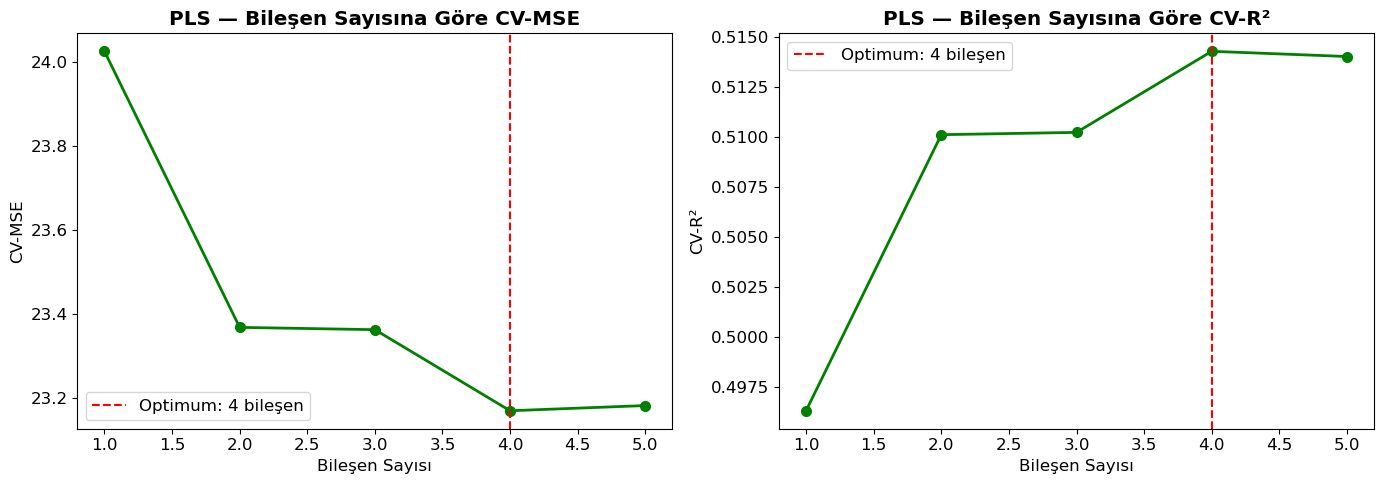

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(range(1, n_max+1), mse_pls_list, 'go-', lw=2, markersize=7)
axes[0].axvline(optimum_pls_n, color='red', linestyle='--', label=f'Optimum: {optimum_pls_n} bileşen')
axes[0].set_xlabel('Bileşen Sayısı')
axes[0].set_ylabel('CV-MSE')
axes[0].set_title('PLS — Bileşen Sayısına Göre CV-MSE', fontweight='bold')
axes[0].legend()

axes[1].plot(range(1, n_max+1), r2_pls_list, 'go-', lw=2, markersize=7)
axes[1].axvline(optimum_pls_n, color='red', linestyle='--', label=f'Optimum: {optimum_pls_n} bileşen')
axes[1].set_xlabel('Bileşen Sayısı')
axes[1].set_ylabel('CV-R²')
axes[1].set_title('PLS — Bileşen Sayısına Göre CV-R²', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

## 5. Model Analizi: PLS Bileşen Optimizasyonu ve Test Performansı

### 5.1 Bileşen Sayısı Optimizasyonu

Çapraz doğrulama (Cross-Validation) analizi, iki farklı metrik üzerinden tutarlı bir sonuç ortaya koymuştur:

| Bileşen Sayısı | CV-MSE | CV-R² |
|:-:|:-:|:-:|
| 1–3 | Yüksek hata | Düşük açıklayıcılık |
| **4** | **Minimum** | **~0.5135 (Zirve)** |
| 5+ | Artış eğilimi | Düşüş |

- **CV-MSE (Sol Grafik):** Bileşen sayısı 1'den 4'e çıkarken hata belirgin biçimde azalmış; 4. bileşenden sonra hata tekrar artmaya başlamıştır.
- **CV-R² (Sağ Grafik):** R² değeri 4. bileşende ~0.5135 ile zirveye ulaşmış, 5. bileşenden itibaren düşüşe geçmiştir.

> Her iki metrik de **optimum bileşen sayısının 4 olduğunu** tutarlı biçimde doğrulamaktadır. 4'ü aşan bileşen sayıları muhtemelen **aşırı öğrenmeye (overfitting)** yol açmaktadır.

---

### 5.2 Test Seti Performansı

4 bileşenli final model, hiç görülmemiş test verileri üzerinde aşağıdaki sonuçları vermiştir:

| Metrik | Değer | Yorum |
|:--|:-:|:--|
| **R²** | ~0.51 | Varyansın %51'i açıklanıyor |
| **RMSE** | ~23.2 | CV-MSE değerleriyle uyumlu |

- **R² ≈ 0.51:** Model, hedef değişkendeki değişkenliğin yaklaşık yarısını açıklayabilmektedir. Bu değer karmaşık fiziksel ölçümler için kabul edilebilir bir başlangıç noktası olmakla birlikte, geliştirme potansiyeli mevcuttur.
- **RMSE ≈ 23.2:** Çapraz doğrulama sırasında gözlemlenen hata değerleriyle uyumlu olması, modelin **tutarlı ve genellenebilir** olduğunu göstermektedir.

Optimizasyon süreci başarılı biçimde tamamlanmış; dirsek noktası **(elbow point) net olarak 4. bileşende** belirlenmiştir. Model, test setinde de tutarlı performans sergileyerek aşırı öğrenme belirtisi göstermemiştir.

R² değerinin 0.51 düzeyinde kalması, modelin veriyi kısmen açıkladığına işaret etmektedir. 

In [18]:
pls_final = PLSRegression(n_components=optimum_pls_n).fit(x_egitim, y_egitim)
preds_pls = pls_final.predict(x_test).ravel()
rmse_pls = np.sqrt(mean_squared_error(y_test, preds_pls))
r2_pls = r2_score(y_test, preds_pls)
print(f'\nPLS Test Seti Performansı (n={optimum_pls_n}):')
print(f'  RMSE : {rmse_pls:.4f}')
print(f'  R²   : {r2_pls:.4f}')
sonuclar['PLS'] = {'RMSE': rmse_pls, 'R2': r2_pls}


PLS Test Seti Performansı (n=4):
  RMSE : 4.8676
  R²   : 0.4982


---
## 8. K-En Yakın Komşu (KNN) Regresyonu

KNN, parametrik olmayan bir yöntemdir. Tahmin edilmek istenen gözleme en yakın k gözlemin hedef değişken ortalamasını tahmin olarak kullanır. k sayısının seçimi modelin performansını doğrudan etkiler. Küçük k → overfitting, büyük k → underfitting riski.

In [19]:
mse_knn = []
r2_knn_list = []
k_araligi = range(1, 31)

for k in k_araligi:
    knn_m = KNeighborsRegressor(n_neighbors=k).fit(x_egitim, y_egitim)
    y_hat = knn_m.predict(x_test)
    mse_knn.append(mean_squared_error(y_test, y_hat))
    r2_knn_list.append(r2_score(y_test, y_hat))

optimum_k = k_araligi[np.argmin(mse_knn)]
print(f'Optimum k değeri: {optimum_k}  (MSE: {mse_knn[optimum_k-1]:.4f})')

Optimum k değeri: 13  (MSE: 36.5627)


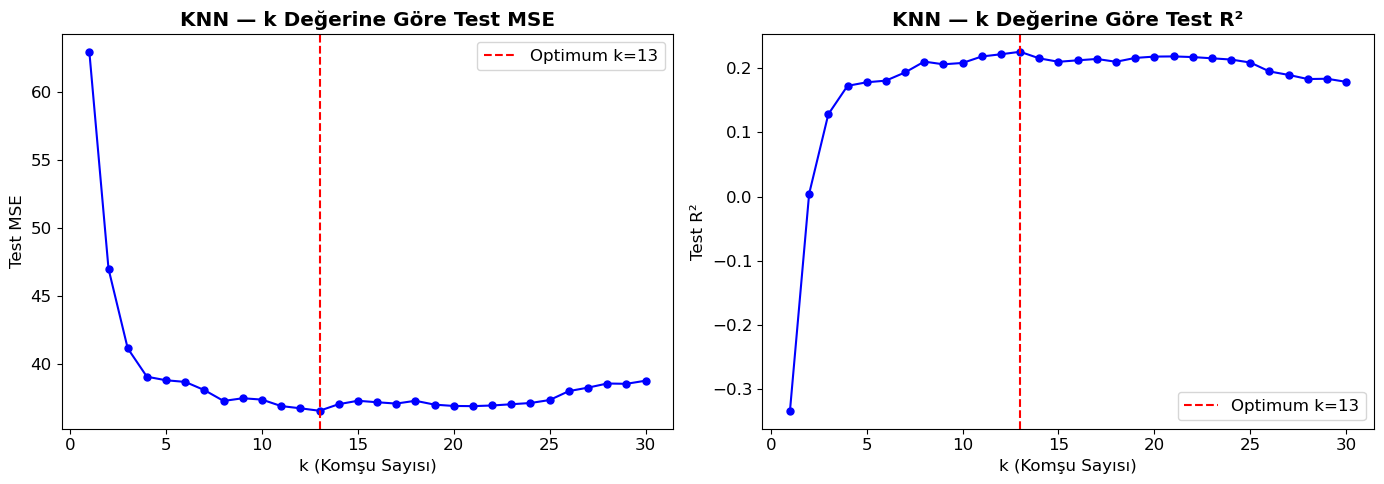

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_araligi), mse_knn, 'b-o', markersize=5)
axes[0].axvline(optimum_k, color='red', linestyle='--', label=f'Optimum k={optimum_k}')
axes[0].set_xlabel('k (Komşu Sayısı)')
axes[0].set_ylabel('Test MSE')
axes[0].set_title('KNN — k Değerine Göre Test MSE', fontweight='bold')
axes[0].legend()

axes[1].plot(list(k_araligi), r2_knn_list, 'b-o', markersize=5)
axes[1].axvline(optimum_k, color='red', linestyle='--', label=f'Optimum k={optimum_k}')
axes[1].set_xlabel('k (Komşu Sayısı)')
axes[1].set_ylabel('Test R²')
axes[1].set_title('KNN — k Değerine Göre Test R²', fontweight='bold')
axes[1].legend()

plt.tight_layout()
plt.show()

## 6. Model Analizi: KNN Hiperparametre Optimizasyonu (k Değeri)

### 6.1 k Değeri Optimizasyonu

| k Değeri | Test MSE | Test R² | Durum |
|:-:|:-:|:-:|:--|
| k < 13 | Yüksek / Azalıyor | Negatif / Artıyor | Overfitting bölgesi |
| **k = 13** | **~36–37 (Min.)** | **~0.20 (Zirve)** | **Optimum** |
| k > 13 | Artış eğilimi | Düşüş | Underfitting bölgesi |

Her iki metrik de optimum k değerinin **13** olduğunu tutarlı biçimde doğrulamaktadır. k = 1'de negatif seyreden R² skoru, k = 13'e kadar düzenli artış göstermiş; bu noktadan itibaren her iki metrikte de bozulma gözlemlenmiştir.

---

### 6.2 Performans Değerlendirmesi 

R² ≈ 0.20, modelin hedef değişkendeki varyansın yalnızca **%20'sini** açıklayabildiğini göstermektedir. Bu değer, KNN'nin mesafeye dayalı yapısının gürültülü ve yüksek boyutlu veri setlerinde sınırlı kalabilmesinden kaynaklanmaktadır.



In [21]:
knn_final = KNeighborsRegressor(n_neighbors=optimum_k).fit(x_egitim, y_egitim)
preds_knn = knn_final.predict(x_test)

rmse_knn = np.sqrt(mean_squared_error(y_test, preds_knn))
r2_knn_val = r2_score(y_test, preds_knn)

print(f'KNN (k={optimum_k}) — Test Seti Performansı:')
print(f'RMSE : {rmse_knn:.4f}')
print(f'R²   : {r2_knn_val:.4f}')

sonuclar['KNN'] = {'RMSE': rmse_knn, 'R2': r2_knn_val}

KNN (k=13) — Test Seti Performansı:
RMSE : 6.0467
R²   : 0.2256


---
## 9. Destek Vektör Regresyonu (SVR)

SVR, bir bant (epsilon-tube) içinde kalan noktaları göz ardı ederek hata payını minimize eden bir modeldir. **Doğrusal kernel** (linear) ve **RBF kernel** (radial basis function) olmak üzere iki seçenek karşılaştırılmaktadır.

In [22]:
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Standartlaştırma
scaler = StandardScaler()
x_egitim_s = scaler.fit_transform(x_egitim)
x_test_s = scaler.transform(x_test)

# Doğrusal SVR
svr_lin = SVR(kernel='linear', max_iter=3000).fit(x_egitim_s, y_egitim)
preds_svr_lin = svr_lin.predict(x_test_s)
rmse_svr_lin = np.sqrt(mean_squared_error(y_test, preds_svr_lin))
r2_svr_lin = r2_score(y_test, preds_svr_lin)
print('Doğrusal SVR Sonuçları:')
print(f'  RMSE : {rmse_svr_lin:.4f}')
print(f'  R²   : {r2_svr_lin:.4f}')

# RBF SVR
svr_rbf = SVR(kernel='rbf').fit(x_egitim_s, y_egitim)
preds_svr_rbf = svr_rbf.predict(x_test_s)
rmse_svr_rbf = np.sqrt(mean_squared_error(y_test, preds_svr_rbf))
r2_svr_rbf = r2_score(y_test, preds_svr_rbf)
print('\nRBF SVR Sonuçları:')
print(f'  RMSE : {rmse_svr_rbf:.4f}')
print(f'  R²   : {r2_svr_rbf:.4f}')

Doğrusal SVR Sonuçları:
  RMSE : 4.9077
  R²   : 0.4898

RBF SVR Sonuçları:
  RMSE : 3.9896
  R²   : 0.6629


In [23]:
from sklearn.model_selection import GridSearchCV

# C parametresi optimizasyonu (doğrusal SVR)
params_svr = {'C': [0.1, 0.5, 1.0, 1.5, 2.0]}
svr_grid = GridSearchCV(SVR(kernel='linear'), params_svr, cv=5, 
                        scoring='neg_mean_squared_error', n_jobs=-1)
svr_grid.fit(x_egitim_s, y_egitim)
best_C = svr_grid.best_params_['C']
print(f'Optimum C değeri: {best_C}')

svr_final = SVR(kernel='linear', C=best_C).fit(x_egitim_s, y_egitim)
preds_svr = svr_final.predict(x_test_s)
rmse_svr = np.sqrt(mean_squared_error(y_test, preds_svr))
r2_svr = r2_score(y_test, preds_svr)
print(f'\nOptimize Edilmiş SVR (Linear, C={best_C:.1f}) — Test Seti Performansı:')
print(f'RMSE : {rmse_svr:.4f}')
print(f'R²   : {r2_svr:.4f}')

sonuclar['SVR (Linear)'] = {'RMSE': rmse_svr_lin, 'R2': r2_svr_lin}
sonuclar['SVR (RBF)'] = {'RMSE': rmse_svr_rbf, 'R2': r2_svr_rbf}

Optimum C değeri: 0.1

Optimize Edilmiş SVR (Linear, C=0.1) — Test Seti Performansı:
RMSE : 4.9091
R²   : 0.4896


---
## 10. Yapay Sinir Ağları (ANN / MLP Regressor)

Yapay sinir ağları, biyolojik sinir sisteminden ilham alınarak geliştirilmiş çok katmanlı modellerdir. Girdi, gizli ve çıktı katmanlarından oluşur. Standartlaştırılmış veri gerektirir.

In [24]:

# Temel ANN modeli
ann_model = MLPRegressor(max_iter=500, random_state=42).fit(x_egitim_s, y_egitim)
print(f'Katman sayısı : {ann_model.n_layers_}')
print(f'Gizli katman boyutu: {ann_model.hidden_layer_sizes}')

preds_ann = ann_model.predict(x_test_s)
rmse_ann_base = np.sqrt(mean_squared_error(y_test, preds_ann))
r2_ann_base = r2_score(y_test, preds_ann)

print(f'\nTemel ANN — Test Seti Performansı:')
print(f'RMSE : {rmse_ann_base:.4f}')
print(f'R²   : {r2_ann_base:.4f}')

Katman sayısı : 3
Gizli katman boyutu: (100,)

Temel ANN — Test Seti Performansı:
RMSE : 8.9445
R²   : -0.6945


In [25]:
ann_params = {
    'hidden_layer_sizes': [(50,), (100, 50), (100, 100)],
    'alpha': [0.001, 0.01]
}
ann_grid = GridSearchCV(
    MLPRegressor(max_iter=300, random_state=42),
    ann_params, cv=3, scoring='neg_mean_squared_error', n_jobs=-1
)
ann_grid.fit(x_egitim_s, y_egitim)
print('En iyi parametreler:', ann_grid.best_params_)

best_ann = ann_grid.best_estimator_
preds_ann_best = best_ann.predict(x_test_s)
rmse_ann = np.sqrt(mean_squared_error(y_test, preds_ann_best))
r2_ann = r2_score(y_test, preds_ann_best)
print(f'RMSE : {rmse_ann:.4f}')
print(f'R²   : {r2_ann:.4f}')

sonuclar['ANN (MLP)'] = {'RMSE': rmse_ann, 'R2': r2_ann}

En iyi parametreler: {'alpha': 0.01, 'hidden_layer_sizes': (100, 100)}
RMSE : 4.0231
R²   : 0.6572


---
## 11. Karar Ağacı Regresyonu (Decision Tree)

Karar ağaçları, veriyi özyinelemeli bölmelerle ayırarak tahmin yapan kural tabanlı modellerdir. Yorumlanabilirliği yüksektir ancak aşırı öğrenmeye (overfitting) eğilimlidir. `max_leaf_nodes` ve `min_samples_split` parametreleriyle kontrol edilir.

In [26]:
cart_model = DecisionTreeRegressor(random_state=42).fit(x_egitim, y_egitim)

# Eğitim performansı
fitted_cart = cart_model.predict(x_egitim)
print('Eğitim Seti Performansı (Overfitting kontrolü):')
print(f'  RMSE : {np.sqrt(mean_squared_error(y_egitim, fitted_cart)):.4f}')
print(f'  R²   : {r2_score(y_egitim, fitted_cart):.4f}')

# Test performansı
preds_cart_base = cart_model.predict(x_test)
print('\nTest Seti Performansı:')
print(f'  RMSE : {np.sqrt(mean_squared_error(y_test, preds_cart_base)):.4f}')
print(f'  R²   : {r2_score(y_test, preds_cart_base):.4f}')
print('\n(Eğitim R²=1.0 ise overfitting var — grid search ile düzeltelim)')

Eğitim Seti Performansı (Overfitting kontrolü):
  RMSE : 0.0000
  R²   : 1.0000

Test Seti Performansı:
  RMSE : 2.9915
  R²   : 0.8105

(Eğitim R²=1.0 ise overfitting var — grid search ile düzeltelim)


In [27]:
cart_pars = {
    'min_samples_split': range(2, 60, 5),
    'max_leaf_nodes': range(2, 15)
}

grid_cart = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    cart_pars, cv=5, scoring='neg_mean_squared_error', n_jobs=-1
)
grid_cart.fit(x_egitim, y_egitim)
print('En iyi parametreler:', grid_cart.best_params_)

best_cart = grid_cart.best_estimator_
preds_cart = best_cart.predict(x_test)
rmse_cart = np.sqrt(mean_squared_error(y_test, preds_cart))
r2_cart = r2_score(y_test, preds_cart)

print(f'\nOptimize Edilmiş Karar Ağacı — Test Seti Performansı:')
print(f'RMSE : {rmse_cart:.4f}')
print(f'R²   : {r2_cart:.4f}')

sonuclar['Karar Ağacı'] = {'RMSE': rmse_cart, 'R2': r2_cart}

En iyi parametreler: {'max_leaf_nodes': 14, 'min_samples_split': 2}

Optimize Edilmiş Karar Ağacı — Test Seti Performansı:
RMSE : 4.6351
R²   : 0.5450


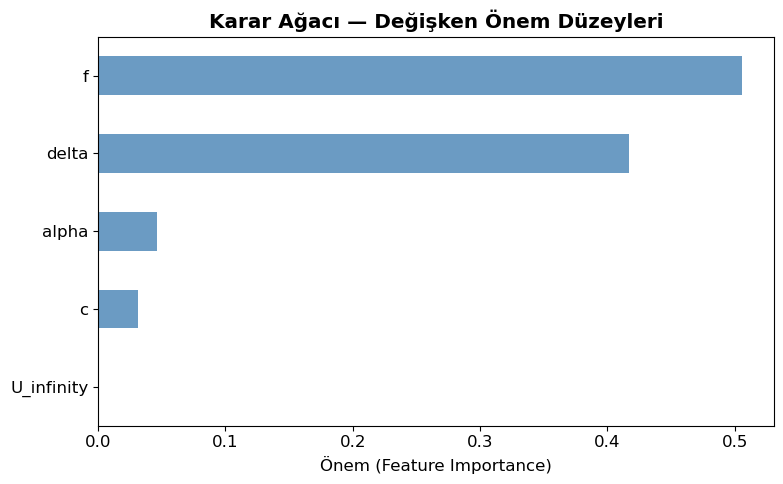

In [28]:
# Değişken önem düzeyleri
importances = best_cart.feature_importances_
feat_imp = pd.Series(importances, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
feat_imp.plot(kind='barh', color='steelblue', alpha=0.8)
plt.title('Karar Ağacı — Değişken Önem Düzeyleri', fontweight='bold')
plt.xlabel('Önem (Feature Importance)')
plt.tight_layout()
plt.show()

---
## 12. Bagging Regresyonu

Bagging (Bootstrap Aggregating), birden fazla karar ağacını bootstrap örneklemesi ile eğiterek tahminlerin ortalamasını alır. Tek bir karar ağacına kıyasla varyansı azaltarak daha kararlı sonuçlar üretir.

In [29]:
bag_model = BaggingRegressor(n_estimators=100, random_state=42).fit(x_egitim, y_egitim)

preds_bag_base = bag_model.predict(x_test)
print('Temel Bagging (100 ağaç) — Test Seti:')
print(f'  RMSE : {np.sqrt(mean_squared_error(y_test, preds_bag_base)):.4f}')
print(f'  R²   : {r2_score(y_test, preds_bag_base):.4f}')

Temel Bagging (100 ağaç) — Test Seti:
  RMSE : 1.8699
  R²   : 0.9259


In [30]:
bag_pars = {'n_estimators': range(10, 110, 10)}
grid_bag = GridSearchCV(
    BaggingRegressor(random_state=42),
    bag_pars, cv=5, scoring='neg_mean_squared_error', n_jobs=-1
)
grid_bag.fit(x_egitim, y_egitim)
print('En iyi n_estimators:', grid_bag.best_params_)

best_bag = grid_bag.best_estimator_
preds_bag = best_bag.predict(x_test)
rmse_bag = np.sqrt(mean_squared_error(y_test, preds_bag))
r2_bag = r2_score(y_test, preds_bag)

print(f'\nOptimize Edilmiş Bagging — Test Seti Performansı:')
print(f'RMSE : {rmse_bag:.4f}')
print(f'R²   : {r2_bag:.4f}')

sonuclar['Bagging'] = {'RMSE': rmse_bag, 'R2': r2_bag}

En iyi n_estimators: {'n_estimators': 100}

Optimize Edilmiş Bagging — Test Seti Performansı:
RMSE : 1.8699
R²   : 0.9259


---
## 13. Random Forest Regresyonu

Random Forest, bagging yöntemini geliştirerek her ağaçta kullanılan değişken setini de rastgeleleştirir (`max_features`). Bu sayede ağaçlar arasındaki korelasyonu azaltır ve daha güçlü bir toplu model oluşturur.

In [31]:
rf_model = RandomForestRegressor(random_state=42).fit(x_egitim, y_egitim)

preds_rf_base = rf_model.predict(x_test)
print('Temel Random Forest — Test Seti:')
print(f'  RMSE : {np.sqrt(mean_squared_error(y_test, preds_rf_base)):.4f}')
print(f'  R²   : {r2_score(y_test, preds_rf_base):.4f}')

Temel Random Forest — Test Seti:
  RMSE : 1.8560
  R²   : 0.9270


In [32]:
rf_model = RandomForestRegressor(random_state=42).fit(x_egitim, y_egitim)
preds_rf_base = rf_model.predict(x_test)
print('Temel Random Forest — Test Seti:')
print(f'  RMSE : {np.sqrt(mean_squared_error(y_test, preds_rf_base)):.4f}')
print(f'  R²   : {r2_score(y_test, preds_rf_base):.4f}')

rf_pars = {
    'max_depth': [5, 10, None],
    'max_features': [2, 3, 4],
    'n_estimators': [100, 300]
}
grid_rf = GridSearchCV(
    RandomForestRegressor(random_state=42),
    rf_pars, cv=3, scoring='neg_mean_squared_error', n_jobs=-1
)
grid_rf.fit(x_egitim, y_egitim)
print('En iyi parametreler:', grid_rf.best_params_)

best_rf = grid_rf.best_estimator_
preds_rf = best_rf.predict(x_test)
rmse_rf = np.sqrt(mean_squared_error(y_test, preds_rf))
r2_rf = r2_score(y_test, preds_rf)
print(f'\nOptimize Edilmiş Random Forest — Test Seti Performansı:')
print(f'RMSE : {rmse_rf:.4f}')
print(f'R²   : {r2_rf:.4f}')

sonuclar['Random Forest'] = {'RMSE': rmse_rf, 'R2': r2_rf}

Temel Random Forest — Test Seti:
  RMSE : 1.8560
  R²   : 0.9270
En iyi parametreler: {'max_depth': None, 'max_features': 4, 'n_estimators': 300}

Optimize Edilmiş Random Forest — Test Seti Performansı:
RMSE : 1.8157
R²   : 0.9302


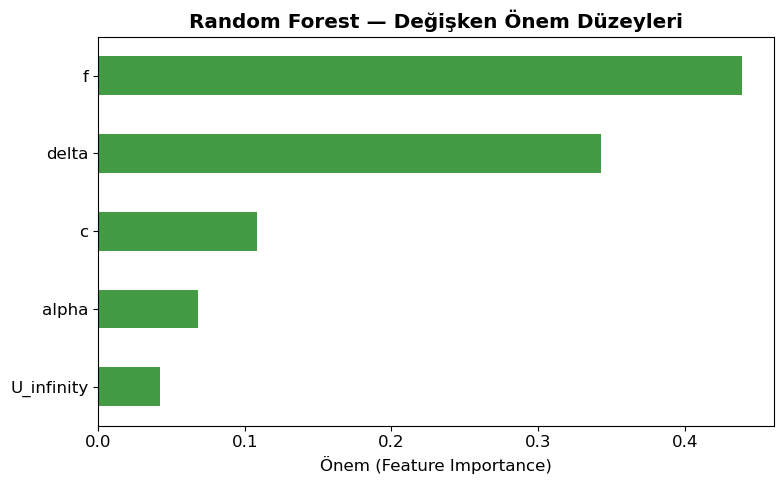

In [33]:
# Değişken önem düzeyleri — Random Forest
rf_importances = pd.Series(best_rf.feature_importances_, index=X.columns).sort_values(ascending=True)

plt.figure(figsize=(8, 5))
rf_importances.plot(kind='barh', color='forestgreen', alpha=0.85)
plt.title('Random Forest — Değişken Önem Düzeyleri', fontweight='bold')
plt.xlabel('Önem (Feature Importance)')
plt.tight_layout()
plt.show()

---
## 14. Gradient Boosting Regresyonu

Gradient Boosting, her yeni ağacı bir önceki modelin hatasını düzeltmek için art arda eğitir. Hem güçlü hem de hızlıdır. `learning_rate`, `n_estimators`, `max_depth` ve `subsample` en kritik hiperparametrelerdir.

In [34]:
gb_model = GradientBoostingRegressor(random_state=42).fit(x_egitim, y_egitim)

preds_gb_base = gb_model.predict(x_test)
print('Temel Gradient Boosting — Test Seti:')
print(f'  RMSE : {np.sqrt(mean_squared_error(y_test, preds_gb_base)):.4f}')
print(f'  R²   : {r2_score(y_test, preds_gb_base):.4f}')

Temel Gradient Boosting — Test Seti:
  RMSE : 2.7865
  R²   : 0.8355


In [35]:

gb_pars = {
    'learning_rate': [0.05, 0.1, 0.2],
    'n_estimators': [100, 300],
    'max_depth': [3, 5]
}
grid_gb = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    gb_pars, cv=3, scoring='neg_mean_squared_error', n_jobs=-1
)
grid_gb.fit(x_egitim, y_egitim)
print('En iyi parametreler:', grid_gb.best_params_)

best_gb = grid_gb.best_estimator_
preds_gb = best_gb.predict(x_test)
rmse_gb = np.sqrt(mean_squared_error(y_test, preds_gb))
r2_gb = r2_score(y_test, preds_gb)
print(f'\nOptimize Edilmiş Gradient Boosting — Test Seti Performansı:')
print(f'RMSE : {rmse_gb:.4f}')
print(f'R²   : {r2_gb:.4f}')

sonuclar['Gradient Boosting'] = {'RMSE': rmse_gb, 'R2': r2_gb}

En iyi parametreler: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 300}

Optimize Edilmiş Gradient Boosting — Test Seti Performansı:
RMSE : 1.5776
R²   : 0.9473


---
## 15. Model Karşılaştırması ve Sonuç

In [36]:
sonuc_df = pd.DataFrame(sonuclar).T.round(4)
sonuc_df = sonuc_df.sort_values('RMSE')
sonuc_df.index.name = 'Model'
print('=== TÜM MODELLER KARŞILAŞTIRMASI (Test Seti) ===')
print(sonuc_df.to_string())

=== TÜM MODELLER KARŞILAŞTIRMASI (Test Seti) ===
                      RMSE      R2
Model                             
Gradient Boosting   1.5776  0.9473
Random Forest       1.8157  0.9302
Bagging             1.8699  0.9259
SVR (RBF)           3.9896  0.6629
ANN (MLP)           4.0231  0.6572
Karar Ağacı         4.6351  0.5450
Doğrusal Regresyon  4.8670  0.4983
PLS                 4.8676  0.4982
SVR (Linear)        4.9077  0.4898
PCR                 4.9213  0.4870
KNN                 6.0467  0.2256


## Model Karşılaştırması ve Genel Değerlendirme

Tüm modeller test seti üzerinde değerlendirilmiş olup sonuçlar aşağıda özetlenmiştir.

### Sonuçlar

| Sıra | Model | RMSE | R² |
|:----:|-------|:----:|:--:|
| 1 | **Gradient Boosting** ★ | 1.5776 | 0.9473 |
| 2 | Random Forest | 1.8157 | 0.9302 |
| 3 | Bagging | 1.8699 | 0.9259 |
| 4 | SVR (RBF) | 3.9896 | 0.6629 |
| 5 | ANN (MLP) | 4.0231 | 0.6572 |
| 6 | Karar Ağacı | 4.6351 | 0.5450 |
| 7 | Doğrusal Regresyon | 4.8670 | 0.4983 |
| 8 | PLS | 4.8676 | 0.4982 |
| 9 | SVR (Linear) | 4.9077 | 0.4898 |
| 10 | PCR | 4.9213 | 0.4870 |
| 11 | KNN | 6.0467 | 0.2256 |

### Genel Yorum

Sonuçlar incelendiğinde modeller üç belirgin gruba ayrılmaktadır:

- **Ensemble yöntemler (Gradient Boosting, Random Forest, Bagging):** En yüksek performansı sergileyen grup. R² değerleri 0.92'nin üzerinde olup RMSE 2 dB'nin altındadır. Bu modeller verinin doğrusal olmayan yapısını başarıyla öğrenmiştir.

- **Orta grup (SVR-RBF, ANN):** R² değerleri 0.65–0.67 aralığındadır. Doğrusal olmayan ilişkileri kısmen yakalayabilmişlerdir ancak ensemble yöntemlerin gerisinde kalmışlardır.

- **Doğrusal modeller (Doğrusal Regresyon, PLS, PCR, SVR-Linear, KNN):** R² değerleri yaklaşık 0.50 civarında seyretmektedir. Bu durum, veri setindeki ilişkilerin büyük ölçüde doğrusal olmadığını açıkça ortaya koymaktadır.

**En iyi model: Gradient Boosting** — RMSE=1.5776, R²=0.9473 ile gürültü seviyesindeki değişimlerin **%94.7'sini** açıklamaktadır.

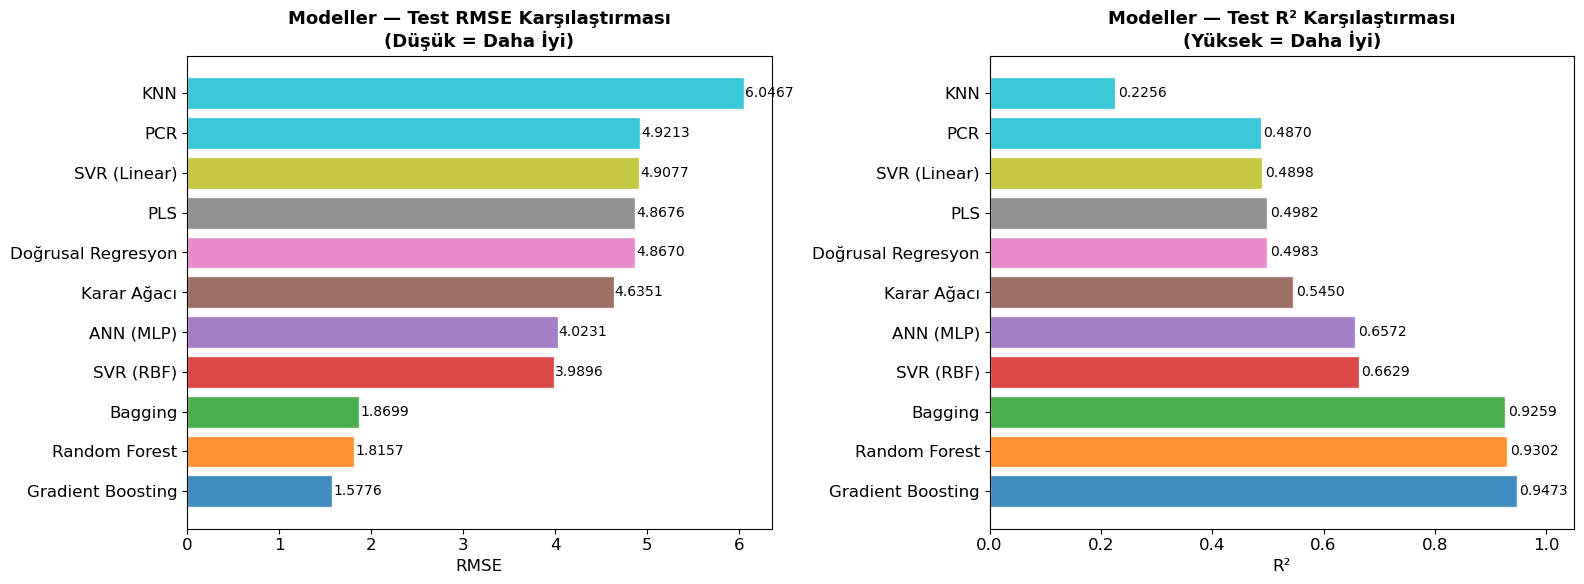

In [37]:
ig, axes = plt.subplots(1, 2, figsize=(16, 6))

renk_listesi = plt.cm.tab10(np.linspace(0, 1, len(sonuc_df)))

# RMSE karşılaştırma
bars1 = axes[0].barh(sonuc_df.index, sonuc_df['RMSE'], color=renk_listesi, alpha=0.85, edgecolor='white')
axes[0].set_title('Modeller — Test RMSE Karşılaştırması\n(Düşük = Daha İyi)', fontweight='bold', fontsize=13)
axes[0].set_xlabel('RMSE')
for bar, val in zip(bars1, sonuc_df['RMSE']):
    axes[0].text(val + 0.01, bar.get_y() + bar.get_height()/2,
                 f'{val:.4f}', va='center', fontsize=10)

# R² karşılaştırma
bars2 = axes[1].barh(sonuc_df.index, sonuc_df['R2'], color=renk_listesi, alpha=0.85, edgecolor='white')
axes[1].set_title('Modeller — Test R² Karşılaştırması\n(Yüksek = Daha İyi)', fontweight='bold', fontsize=13)
axes[1].set_xlabel('R²')
axes[1].set_xlim(0, 1.05)
for bar, val in zip(bars2, sonuc_df['R2']):
    axes[1].text(val + 0.005, bar.get_y() + bar.get_height()/2,
                 f'{val:.4f}', va='center', fontsize=10)

plt.tight_layout()
plt.show()

In [38]:
en_iyi_model_adi = sonuc_df.index[0]
en_iyi_rmse = sonuc_df.iloc[0]['RMSE']
en_iyi_r2 = sonuc_df.iloc[0]['R2']

print(f'✅ EN İYİ MODEL: {en_iyi_model_adi}')
print(f'   RMSE : {en_iyi_rmse:.4f}')
print(f'   R²   : {en_iyi_r2:.4f}')

✅ EN İYİ MODEL: Gradient Boosting
   RMSE : 1.5776
   R²   : 0.9473


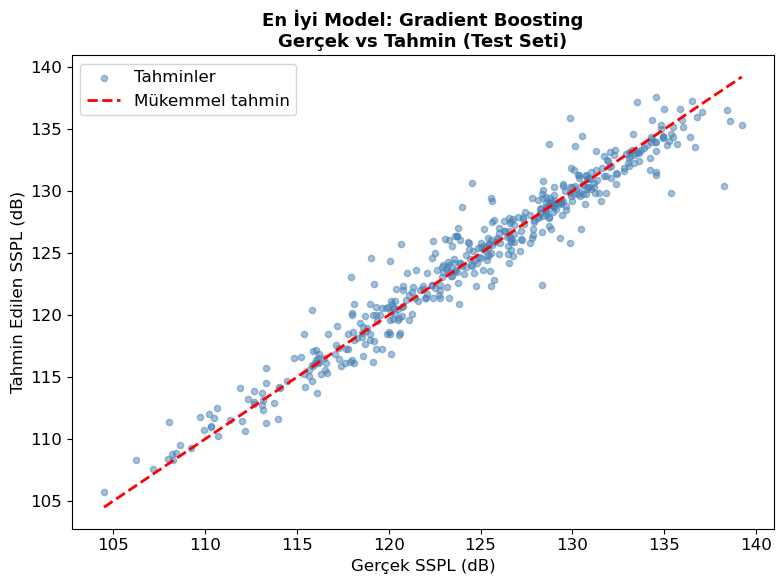

In [39]:
# En iyi model — gerçek vs tahmin saçılım grafiği
model_preds_map = {
    'Gradient Boosting': preds_gb,
    'Random Forest': preds_rf,
    'Bagging': preds_bag,
    'ANN (MLP)': preds_ann_best,
    'KNN': preds_knn,
    'SVR (RBF)': preds_svr_rbf,
    'SVR (Linear)': preds_svr_lin,
    'Karar Ağacı': preds_cart,
    'PLS': preds_pls,
    'PCR': preds_pcr,
    'Doğrusal Regresyon': preds_lin
}

en_iyi_preds = model_preds_map.get(en_iyi_model_adi)

plt.figure(figsize=(8, 6))
plt.scatter(y_test, en_iyi_preds, alpha=0.5, color='steelblue', s=20, label='Tahminler')
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],
         'r--', lw=2, label='Mükemmel tahmin')
plt.xlabel('Gerçek SSPL (dB)', fontsize=12)
plt.ylabel('Tahmin Edilen SSPL (dB)', fontsize=12)
plt.title(f'En İyi Model: {en_iyi_model_adi}\nGerçek vs Tahmin (Test Seti)', fontweight='bold', fontsize=13)
plt.legend()
plt.tight_layout()
plt.show()

## Sonuç ve Değerlendirme

Bu çalışmada NASA Airfoil Self-Noise veri seti üzerinde 11 farklı regresyon modeli
uygulanmış ve modeller test seti performanslarına göre karşılaştırılmıştır.
Karşılaştırma sonucunda **Gradient Boosting** modeli en iyi performansı sergilemiştir.

### En İyi Model: Gradient Boosting

| Metrik | Değer | Yorum |
|--------|-------|-------|
| **RMSE** | **1.5776 dB** | Tahminler gerçek değerlerden ortalama ~1.58 dB sapıyor |
| **R²** | **0.9473** | Gürültü değişimlerinin %94.7'si model tarafından açıklanıyor |

### Neden Gradient Boosting?

Gradient Boosting, her adımda bir önceki modelin hatalarını düzelterek öğrenen
bir ensemble yöntemidir. Bu yapı sayesinde:

- Veri setindeki **doğrusal olmayan ilişkileri** başarıyla yakalamıştır.
- Frekans (f) ve sınır tabakası kalınlığı (delta) gibi değişkenlerin SSPL
üzerindeki **karmaşık etkilerini** modelleyebilmiştir.
- Tek başına çalışan doğrusal modellere (R²≈0.50) kıyasla neredeyse
**iki kat daha fazla** varyansı açıklamıştır.

### Doğrusal ve Doğrusal Olmayan Modellerin Karşılaştırması

Doğrusal Regresyon, PLS ve PCR modellerinin R² değerlerinin ~0.50 düzeyinde
kalması, veri setindeki bağımsız değişkenler ile SSPL arasındaki ilişkinin
**doğrusal olmayan bir yapıya** sahip olduğunu açıkça ortaya koymaktadır.
Gradient Boosting bu yapıyı öğrenerek R²=0.9473 değerine ulaşmıştır.

###  Yorum

SSPL değerlerinin 103–140 dB aralığında olduğu göz önüne alındığında,
ortalama **1.58 dB'lik hata payı** oldukça başarılı bir tahmin performansına
işaret etmektedir. Model; frekans, hücum açısı, kanat boyu, akış hızı ve
sınır tabakası kalınlığı bilgileri verildiğinde ses basınç seviyesini
yüksek doğrulukla tahmin edebilmektedir.